# Lab 5: Quantum Approximate Optimization Algorithm (QAOA)

**Course:** Quantum Optimization Lab (QCL7350)

**Topics covered:** The QAOA workflow, Minimum Vertex Cover with QAOA in Qiskit, why classical simulation runs out of road, running the same problem on an IBM Heron r2 QPU

**Tools:** qiskit, qiskit-aer, qiskit-ibm-runtime, networkx, numpy, scipy, matplotlib

**Session length:** 30 minutes. About 15 minutes for QAOA on Minimum Vertex Cover, then about 15 minutes for the QPU demo.

**Builds on:** Lab 1 (QUBO formulation, where we introduced MVC), Lab 2 (MVC and QUBO), Lab 4 (Hamiltonians $H_M$, $H_P$ and Trotterization)

## Learning objectives

By the end of this lab you should be able to:

1. Describe the seven steps of the QAOA workflow and say which part runs on a quantum device and which part runs on a classical computer.
2. Turn the Minimum Vertex Cover QUBO into an Ising cost Hamiltonian written as a `SparsePauliOp`.
3. Build a depth $p$ QAOA circuit and tune its angles $(\gamma, \beta)$ with a classical optimizer.
4. Read the output distribution of a QAOA circuit and decide whether the answer is a valid, optimal cover.
5. Explain, with a measurement from your own machine, why simulating QAOA gets out of reach somewhere in the high 20s of qubits.
6. Read a job on the IBM Quantum Platform and compare QPU time against classical simulation time for the same problem.

> **A note on the QPU part.** The QPU demo is run live by the instructor. Everything else in this notebook, including every in-class task and every exercise, runs on your laptop. You do not need IBM access to finish this lab.

In [1]:
!pip install qiskit qiskit-aer qiskit-ibm-runtime networkx scipy matplotlib pylatexenc -q

In [2]:
import time
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from scipy.optimize import minimize, milp, LinearConstraint, Bounds

import qiskit
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit.visualization import plot_histogram
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_aer import AerSimulator

RNG_SEED = 7
rng = np.random.default_rng(RNG_SEED)

print("qiskit version:", qiskit.__version__)

qiskit version: 2.3.0


---
# Part 0: The QAOA workflow

QAOA is a hybrid algorithm. A quantum circuit prepares a state and gets measured, and a classical optimizer looks at the measurements and decides which angles to try next. The picture below is the loop we will build today, piece by piece.

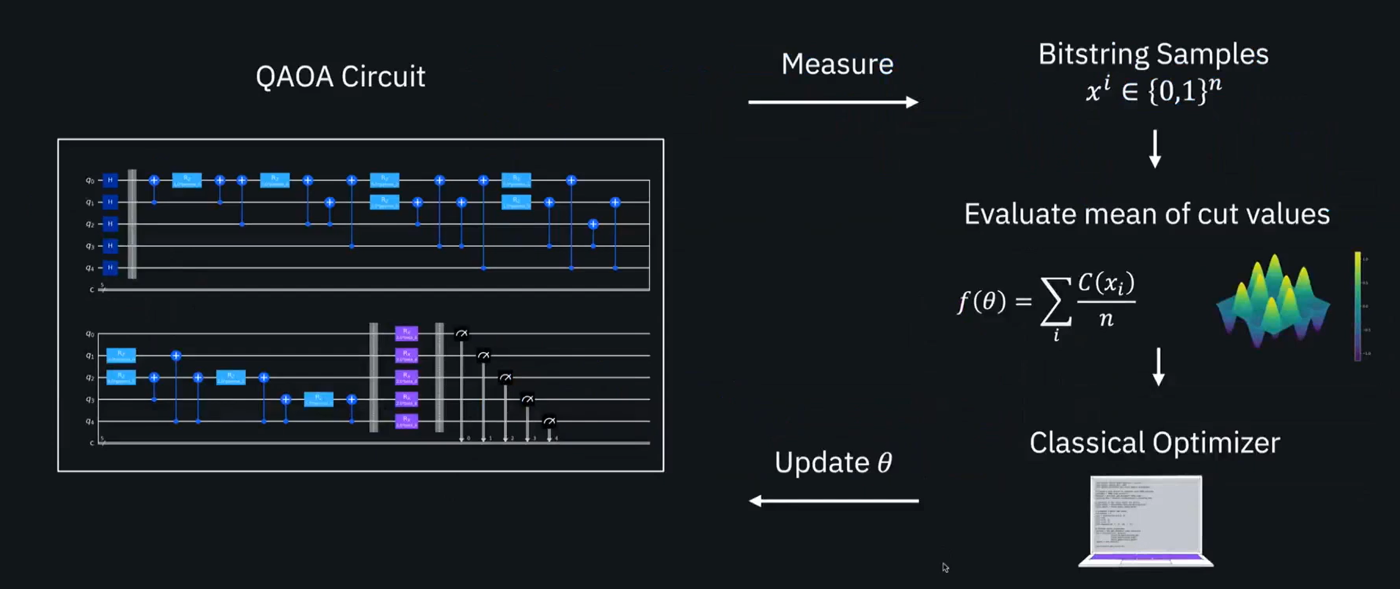

## 🔹 QAOA Workflow

**1. Problem formulation**
- Start with an optimization problem expressed as a cost function $F(x)$.
- Encode it into a QUBO (Quadratic Unconstrained Binary Optimization) form.

**2. Mapping to Hamiltonian**
- Translate the QUBO into an Ising Hamiltonian $H_P$ (the problem Hamiltonian).
- This Hamiltonian encodes the objective function into quantum mechanics.

**3. Define Hamiltonians**
- Cost Hamiltonian $H_P$: represents the optimization objective.
- Mixer Hamiltonian $H_M$: ensures exploration of the solution space.

**4. Trotterization / Circuit construction**
- Use the Trotter-Suzuki decomposition to approximate alternating evolution under $H_P$ and $H_M$.
- Build a parameterized quantum circuit with layers:

$$U(\gamma, \beta) = \prod_{k=1}^{p} e^{-i\beta_k H_M}\, e^{-i\gamma_k H_P}$$

**5. Expectation value evaluation**
- Run the circuit on a quantum device.
- Measure expectation values of $H_P$ to estimate the cost function.

**6. Classical optimization loop**
- Feed the measured expectation values into a classical optimizer.
- Update parameters $\gamma, \beta$.
- Re-run the quantum circuit with new parameters.

**7. Iterate until convergence**
- Repeat the loop until the optimizer converges to parameters that minimize (or maximize) the cost function.
- The final measurement distribution gives the approximate solution.

Today's plan follows these steps in order. Steps 1 to 3 are Section 1.1 and 1.2, step 4 is Section 1.3, steps 5 to 7 are Section 1.4.

> ### Explore Further: QAOA beyond Qiskit
>
> Qiskit is not the only way to write QAOA. PennyLane has a clean interface for QAOA and for general variational quantum algorithms (VQA), and it is worth knowing about because it makes the classical optimization side very convenient.
>
> - **[Intro to QAOA | PennyLane Demos](https://pennylane.ai/demos/tutorial_qaoa_intro)** The same workflow as above, explained from the ground up.
> - **[QAOA for MaxCut | PennyLane Demos](https://pennylane.ai/demos/tutorial_qaoa_maxcut)** A full worked example on Max-Cut, which you will meet again in Exercise 2.

---
# Part 1: Minimum Vertex Cover with QAOA

## 1.1 The problem, quickly

We covered MVC in detail in Lab 1 and Lab 2, so this is just a reminder. Given a graph $G=(V,E)$ we want the smallest set of vertices such that every edge has at least one endpoint inside the set. With one binary variable $x_i$ per vertex ($x_i = 1$ means vertex $i$ is in the cover) the QUBO is

$$F(x) = \sum_{i \in V} x_i \;+\; P \sum_{(i,j)\in E} (1-x_i)(1-x_j)$$

The first term counts guards. The second term charges a penalty $P$ for every edge with no guard on either end. We will use $P = 2$.

Our test graph is a random 3-regular graph on 8 vertices, small enough to check every answer by brute force.

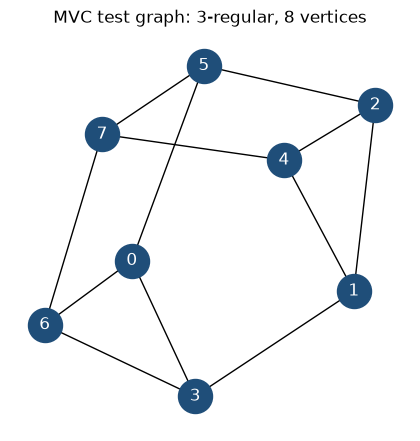

In [3]:
n = 8
G = nx.random_regular_graph(3, n, seed=RNG_SEED)
P = 2.0

plt.figure(figsize=(4, 4))
nx.draw(G, nx.spring_layout(G, seed=RNG_SEED), with_labels=True,
        node_color="#1f4e79", font_color="white", node_size=600)
plt.title("MVC test graph: 3-regular, 8 vertices")
plt.show()

## 1.2 From QUBO to a cost Hamiltonian

Replace each binary variable by a Pauli operator using $x_i = \frac{1 - Z_i}{2}$. Then $1 - x_i = \frac{1+Z_i}{2}$, and expanding the QUBO gives

$$H_P = \sum_i \Big(-\tfrac12 + \tfrac{P\, d_i}{4}\Big) Z_i \;+\; \frac{P}{4}\sum_{(i,j)\in E} Z_i Z_j \;+\; \text{const}, \qquad \text{const} = \frac{n}{2} + \frac{P\,|E|}{4}$$

where $d_i$ is the degree of vertex $i$. The constant does not change which state is best, but we keep it so that the energy of $H_P$ equals the QUBO value $F(x)$ exactly. That makes the numbers easy to read.

In [4]:
def mvc_hamiltonian(G, P=2.0):
    n = G.number_of_nodes()
    terms = [("Z", [i], -0.5 + P * G.degree(i) / 4) for i in G.nodes]
    terms += [("ZZ", [i, j], P / 4) for i, j in G.edges]
    offset = n / 2 + P * G.number_of_edges() / 4
    return SparsePauliOp.from_sparse_list(terms, num_qubits=n), offset

Quick sanity check. $H_P$ is diagonal, so its diagonal entries (plus the offset) are the QUBO values of all $2^8 = 256$ bitstrings. The smallest one is the true optimum.

In [5]:
H, offset = mvc_hamiltonian(G, P)
energies = H.to_matrix(sparse=True).diagonal().real + offset

print(H)
print("Optimal QUBO value (brute force):", energies.min())
print("Number of optimal bitstrings    :", int(np.sum(np.isclose(energies, energies.min()))))

SparsePauliOp(['IIIIIIIZ', 'IIIIIIZI', 'IIIIIZII', 'IIIIZIII', 'IIIZIIII', 'IIZIIIII', 'IZIIIIII', 'ZIIIIIII', 'IIIIZIIZ', 'IZIIIIIZ', 'IIZIIIIZ', 'IIIIIZZI', 'IIIZIIZI', 'IIIIZIZI', 'IIIZIZII', 'IIZIIZII', 'IZIIZIII', 'ZIIZIIII', 'ZIZIIIII', 'ZZIIIIII'],
              coeffs=[1. +0.j, 1. +0.j, 1. +0.j, 1. +0.j, 1. +0.j, 1. +0.j, 1. +0.j, 1. +0.j,
 0.5+0.j, 0.5+0.j, 0.5+0.j, 0.5+0.j, 0.5+0.j, 0.5+0.j, 0.5+0.j, 0.5+0.j,
 0.5+0.j, 0.5+0.j, 0.5+0.j, 0.5+0.j])
Optimal QUBO value (brute force): 5.0
Number of optimal bitstrings    : 6


## 1.3 Building the QAOA circuit

One layer of QAOA does two things to the qubits:

- **Cost layer** $e^{-i\gamma H_P}$. Every $Z_i$ term becomes an `rz` and every $Z_iZ_j$ term becomes an `rzz`. All these terms commute, so the Trotter step is exact here.
- **Mixer layer** $e^{-i\beta H_M}$ with $H_M = \sum_i X_i$. That is one `rx` on every qubit.

The circuit starts from $|+\rangle^{\otimes n}$, which is the ground state of $H_M$ (up to sign). Recall from Lab 4 that this is where the adiabatic path starts. QAOA is that path chopped into $p$ coarse steps, with the step sizes $\gamma_k, \beta_k$ chosen by an optimizer instead of a schedule.

A small detail: `rz(theta)` is $e^{-i\theta Z/2}$, so $e^{-i\gamma c Z}$ needs the angle $2\gamma c$.

In [6]:
def qaoa_circuit(H, gammas, betas):
    qc = QuantumCircuit(H.num_qubits)
    qc.h(range(H.num_qubits))
    for g, b in zip(gammas, betas):
        for label, idx, coeff in H.to_sparse_list():
            qc.rzz(2 * g * coeff.real, *idx) if label == "ZZ" else qc.rz(2 * g * coeff.real, *idx)
        qc.rx(2 * b, range(H.num_qubits))
    return qc

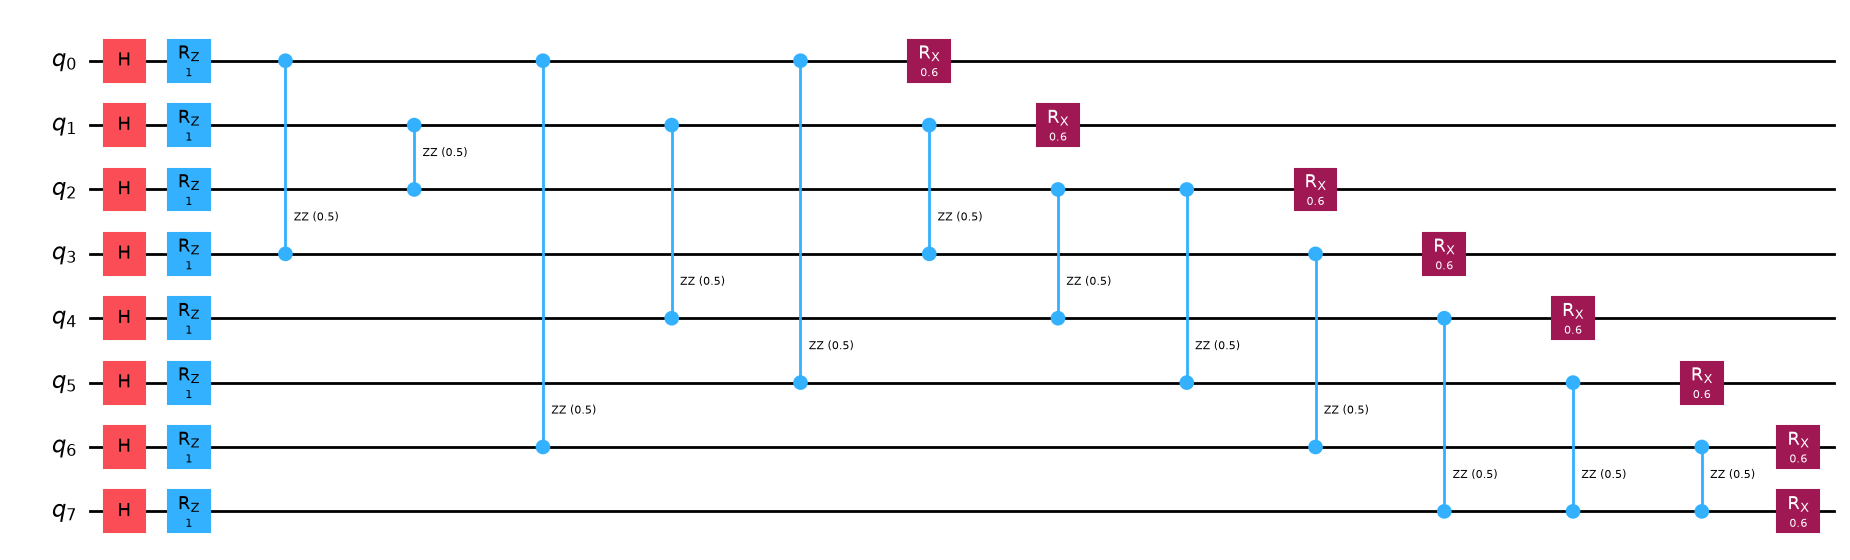

In [7]:
qc_demo = qaoa_circuit(H, [0.5], [0.3])
qc_demo.draw("mpl", fold=45)

## 1.4 Evaluate, optimize, repeat

Steps 5 to 7 of the workflow. The cost of a set of angles is the expectation value $\langle \psi(\gamma,\beta) | H_P | \psi(\gamma,\beta) \rangle$. On a real device we estimate it from many shots. Here we have the full statevector, so we can read it off exactly, which keeps the optimization clean while we learn.

In [8]:
def energy(params, p):
    qc = qaoa_circuit(H, params[:p], params[p:])
    state = Statevector(qc)
    return state.expectation_value(H).real + offset

Before optimizing, notice what random angles give. With $\gamma = \beta = 0$ the state is just $|+\rangle^{\otimes n}$, the uniform superposition, and its average energy is the average QUBO value over all bitstrings. QAOA has to beat that.

In [9]:
print("Uniform superposition energy:", round(energy(np.zeros(2), 1), 3))
print("Mean over all bitstrings    :", round(energies.mean(), 3))
print("True optimum                :", energies.min())

Uniform superposition energy: 10.0
Mean over all bitstrings    : 10.0
True optimum                : 5.0


Now the classical half of the loop. We use COBYLA, a derivative free optimizer that is a good default for noisy, small parameter problems. We wrap `energy` so that every call is recorded, which lets us plot the convergence afterwards.

In [10]:
p = 1
history = []

def objective(x):
    e = energy(x, p)
    history.append(e)
    return e

x0 = rng.uniform(0, np.pi, 2 * p)
res = minimize(objective, x0, method="COBYLA", options={"maxiter": 100})

p = 1   final energy = 6.597   optimum = 5.0   circuit evaluations = 32
gamma, beta = [2.775 2.698]


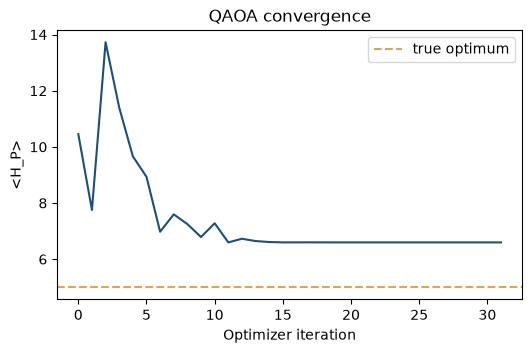

In [11]:
print(f"p = {p}   final energy = {res.fun:.3f}   optimum = {energies.min():.1f}   circuit evaluations = {res.nfev}")
print("gamma, beta =", np.round(res.x, 3))

plt.figure(figsize=(6, 3.5))
plt.plot(history, color="#1f4e79")
plt.axhline(energies.min(), color="#e0a458", linestyle="--", label="true optimum")
plt.xlabel("Optimizer iteration")
plt.ylabel("<H_P>")
plt.title("QAOA convergence")
plt.legend()
plt.show()

The energy fell, but it did not reach the optimum. That is normal. The energy here is an **average** over the output distribution, so even a perfectly tuned $p=1$ circuit puts some weight on bad bitstrings. What we care about is whether the good bitstrings have become the most likely ones.

## 1.5 Reading the answer

In [12]:
final_state = Statevector(qaoa_circuit(H, res.x[:p], res.x[p:]))
probs = final_state.probabilities_dict()
top = sorted(probs.items(), key=lambda kv: -kv[1])[:6]

In [13]:
def to_cover(bits):
    # Qiskit prints qubit 0 on the right, so reverse the string
    return {i for i, b in enumerate(reversed(bits)) if b == "1"}

def is_cover(G, S):
    return all(u in S or v in S for u, v in G.edges)

print("bitstring   probability   cover size   valid cover?")
for bits, pr in top:
    S = to_cover(bits)
    print(f"{bits}    {pr:8.4f}      {len(S):5d}        {is_cover(G, S)}")

p_opt = sum(pr for b, pr in probs.items() if np.isclose(energies[int(b, 2)], energies.min()))
print(f"\nProbability of measuring an optimal cover: {p_opt:.3f}   (random guessing: {np.sum(np.isclose(energies, energies.min())) / 2**n:.3f})")

bitstring   probability   cover size   valid cover?
10111011      0.0264          6        True
11101110      0.0264          6        True
01110011      0.0239          5        True
01111100      0.0239          5        True
11000111      0.0239          5        True
10011101      0.0239          5        True

Probability of measuring an optimal cover: 0.138   (random guessing: 0.023)


Two things to note when you read this table. First, the top bitstrings are mostly valid covers, so the penalty term is doing its job. Second, the probability of an optimal cover is several times better than random guessing, even at $p=1$. That lift is the whole value of QAOA, and on a real device we would sample, check each bitstring classically, and keep the best one.

> **In-class task 1.** Set `p = 2` in section 1.4 and re-run the optimizer cell, the convergence cell and the table cell. Does the final energy get closer to the optimum? Does `p_opt` go up? Note how many circuit evaluations the optimizer needed this time.

In [ ]:
# TODO: in-class task 1 (reuse the cells above)


---
# Part 2: How far can we simulate?

Everything so far used 8 qubits, and each circuit evaluation took a few milliseconds. The catch is that a statevector simulator stores $2^n$ complex numbers, 16 bytes each, and updates all of them for every gate. Memory and time both double with every extra qubit.

Let's measure what one circuit evaluation costs as $n$ grows, and then extrapolate.

## 2.1 Measuring one evaluation

We use `AerSimulator`, which is what a serious local run would use. It can run on a GPU if you have `qiskit-aer-gpu` installed (Linux with CUDA, or WSL2 on Windows). Everything below runs on the CPU by default, so you can follow along on any machine.

In [17]:
DEVICE = "CPU"          # change to "GPU" if qiskit-aer-gpu is installed
sim = AerSimulator(method="statevector", device=DEVICE)

def time_one_eval(n):
    Gn = nx.random_regular_graph(3, n, seed=RNG_SEED)
    Hn, _ = mvc_hamiltonian(Gn, P)
    qc = qaoa_circuit(Hn, [0.4], [0.3])
    qc.save_expectation_value(Hn, list(range(n)))
    tqc = transpile(qc, sim)
    t0 = time.time(); sim.run(tqc).result()
    return time.time() - t0

n = 12 qubits   one evaluation =    0.003 s
n = 14 qubits   one evaluation =    0.008 s
n = 16 qubits   one evaluation =    0.009 s
n = 18 qubits   one evaluation =    0.041 s
n = 20 qubits   one evaluation =    0.271 s
n = 22 qubits   one evaluation =    0.614 s
n = 24 qubits   one evaluation =    2.243 s


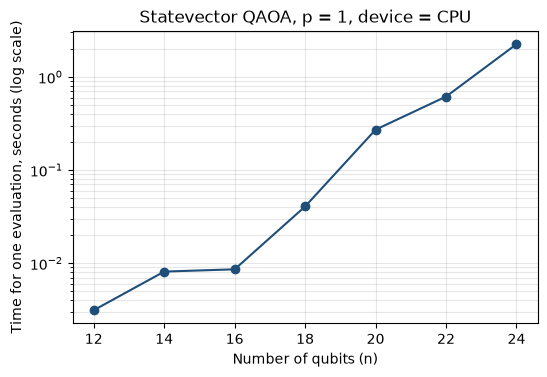

In [18]:
time_one_eval(10)                     # warm-up call, ignore this one
ns = list(range(12, 25, 2))
times = []
for nq in ns:
    times.append(time_one_eval(nq))
    print(f"n = {nq:2d} qubits   one evaluation = {times[-1]:8.3f} s")

plt.figure(figsize=(6, 3.8))
plt.semilogy(ns, times, marker="o", color="#1f4e79")
plt.xlabel("Number of qubits (n)")
plt.ylabel("Time for one evaluation, seconds (log scale)")
plt.title(f"Statevector QAOA, p = 1, device = {DEVICE}")
plt.grid(True, which="both", alpha=0.3)
plt.show()

A straight line on a log axis means exponential growth. Each extra qubit multiplies the time by a roughly constant factor, close to 2.

## 2.2 Extrapolating to bigger problems

We fit a straight line to $\log_2(\text{time})$ against $n$ and extend it. The optimizer in Section 1.4 needed on the order of 50 to 200 evaluations, so we multiply by `N_EVALS` to estimate a whole optimization run. The memory column is $16 \times 2^n$ bytes. Aer also needs scratch space, so as a rule of thumb the GPU needs about twice that.

In [19]:
slope, intercept = np.polyfit(ns, np.log2(times), 1)

def est(n):
    return 2 ** (slope * n + intercept)

In [28]:
N_EVALS = 200
VRAM_GB = 4

def human(sec):
    for unit, size in [("years", 3.15e7), ("days", 86400), ("hours", 3600), ("minutes", 60)]:
        if sec >= size:
            return f"{sec / size:,.1f} {unit}"
    return f"{sec:.1f} seconds"

print(f"Growth factor per extra qubit: {2**slope:.2f}x\n")
print(" n   statevector memory     one evaluation      full run ({} evals)".format(N_EVALS))
for nq in [20, 25, 27, 30, 35, 40, 50]:
    mem = 16 * 2**nq
    fits = "yes" if 2 * mem <= VRAM_GB * 1e9 else "no"
    print(f"{nq:2d}   {mem / 1e9:14,.2f} GB    {human(est(nq)):>15}   {human(est(nq) * N_EVALS):>18}")

Growth factor per extra qubit: 1.77x

 n   statevector memory     one evaluation      full run (200 evals)
20             0.02 GB        0.2 seconds         38.3 seconds
25             0.54 GB        3.3 seconds         10.9 minutes
27             2.15 GB       10.2 seconds         34.1 minutes
30            17.18 GB       56.3 seconds            3.1 hours
35           549.76 GB       16.1 minutes             2.2 days
40        17,592.19 GB          4.6 hours            38.3 days
50    18,014,398.51 GB          56.2 days           30.8 years


Read the table in two parts. Around $n=30$ the *time* for a full optimization run is already hours on a typical laptop, and it climbs to days a few qubits later. But the time column quietly assumes the state fits in memory, so look at the memory column too. On this GPU the hard wall arrives in the mid 20s, because the state simply does not fit. Beyond roughly 45 qubits no classical machine on Earth can hold the state at all.

(There are cleverer classical methods, such as tensor networks, that can handle some shallow circuits well past this point. They work when the entanglement stays low. A general QAOA circuit on a dense graph does not promise that.)

> **In-class task 4.** Change `N_EVALS` to 50 and to 1000 and re-run the table. How does the picture at $n=30$ change? Does it change the picture at $n=50$?

In [ ]:
# TODO: in-class task 4

---
# Part 3: The same problem on an IBM QPU (instructor demo)

Now the same MVC problem, but on a graph with **30 vertices**, which needs 30 qubits. Our table says a single evaluation at this size is far outside what this laptop can hold. A Heron r2 processor has 156 qubits, so 30 is a small job for it.

One honest point before we run. On the QPU we are **not** repeating the 100 optimizer iterations. We reuse the angles we trained on the 8 vertex graph in Section 1.4. This works reasonably well for QAOA on regular graphs, because every vertex of a 3-regular graph sees the same local neighbourhood no matter how big the graph is, so good angles carry over. So the comparison is one circuit evaluation (1024 shots) on the QPU against one statevector evaluation on the laptop. Today's NISQ hardware is also noisy, so we should expect the quality of the answer to be modest. We are here to look at the clock.

The cells below are guarded by `RUN_ON_QPU`. It is `False` by default so that the notebook runs end to end without an IBM account. If you have your own access, set up your account using the IBM Quantum setup guide shared with this lab and flip it to `True`.

In [ ]:
# One time setup. Uncomment, paste your own API key and instance CRN, run once, then comment it out again.
# from qiskit_ibm_runtime import QiskitRuntimeService
# QiskitRuntimeService.save_account(
#     token="YOUR_API_KEY",
#     instance="YOUR_INSTANCE_CRN",
#     overwrite=True,
#     set_as_default=True,
# )

In [29]:
RUN_ON_QPU = False      # flip this to True for execution on IBM Quantum Hardware
N_QPU = 30

G30 = nx.random_regular_graph(3, N_QPU, seed=RNG_SEED)
H30, offset30 = mvc_hamiltonian(G30, P)

qc30 = qaoa_circuit(H30, res.x[:p], res.x[p:])     # angles trained on the 8 vertex graph
qc30.measure_all()
print(f"{N_QPU} qubits, {G30.number_of_edges()} edges, p = {p}")

30 qubits, 45 edges, p = 1


## 3.1 Pick the least busy Heron r2 backend

In [30]:
if RUN_ON_QPU:
    from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler
    service = QiskitRuntimeService()
    heron = service.backends(simulator=False, operational=True, min_num_qubits=N_QPU,
                             filters=lambda b: (b.processor_type or {}).get("family") == "Heron"
                                           and str((b.processor_type or {}).get("revision")) == "2")
    backend = min(heron, key=lambda b: b.status().pending_jobs)
    print("Using:", backend.name, "|", backend.num_qubits, "qubits |", backend.status().pending_jobs, "jobs in queue")

## 3.2 Transpile for the hardware

The QPU does not run our circuit as written. It only supports a small native gate set and only allows two qubit gates between physically connected qubits, so the transpiler rewrites the circuit and inserts swaps where needed. Compare the sizes.

In [31]:
if RUN_ON_QPU:
    isa = generate_preset_pass_manager(optimization_level=3, backend=backend).run(qc30)
    print("Logical circuit  : depth", qc30.depth(), "| two qubit gates", qc30.num_nonlocal_gates())
    print("Hardware circuit : depth", isa.depth(), "| gates", dict(isa.count_ops()))

## 3.3 Run it and watch the clock

In [32]:
if RUN_ON_QPU:
    job = Sampler(mode=backend).run([isa], shots=1024)
    print("Job ID:", job.job_id())
    counts = job.result()[0].data.meas.get_counts()
    print("Status:", job.status(), "| QPU time used (seconds):", job.usage())

Open the **Jobs** page on the [IBM Quantum Platform](https://quantum.cloud.ibm.com/), find this job ID, and look at two different numbers. The **queue wait** depends on how many other people are using the machine and tells us nothing about the algorithm. The **quantum usage** in seconds is the time the QPU itself spent on our 1024 shots. That second number is the one to put next to the table from Section 2.2.

## 3.4 Did it find a good cover?

Raw bitstrings from noisy hardware are often not valid covers. So we add a small classical post processing step that is standard in practice: for every sampled bitstring, fix any uncovered edge by adding one of its endpoints, then drop any vertex that turned out to be redundant. As a control we apply the exact same repair to purely random bitstrings, so we can see whether the QPU sampling actually helped.

In [33]:
def repair(G, S):
    S = set(S)
    for u, v in G.edges:
        if u not in S and v not in S:
            S.add(u if G.degree(u) >= G.degree(v) else v)
    for v in list(S):
        if all(w in S for w in G[v]):
            S.remove(v)
    return S

def mvc_exact(G):
    A = np.zeros((G.number_of_edges(), G.number_of_nodes()))
    for k, (u, v) in enumerate(G.edges):
        A[k, u] = A[k, v] = 1
    out = milp(np.ones(G.number_of_nodes()), constraints=LinearConstraint(A, lb=1),
               integrality=np.ones(G.number_of_nodes()), bounds=Bounds(0, 1))
    return int(round(out.fun))

In [34]:
if RUN_ON_QPU:
    qpu_sizes = [len(repair(G30, to_cover(b))) for b, c in counts.items() for _ in range(c)]
    rand_sizes = [len(repair(G30, to_cover("".join(rng.choice(["0", "1"], N_QPU))))) for _ in range(1024)]

    print("Exact minimum cover (classical solver):", mvc_exact(G30))
    print("Matching 2-approximation              :", len(nx.approximation.min_weighted_vertex_cover(G30)))
    print(f"QPU samples + repair   : best {min(qpu_sizes)}, mean {np.mean(qpu_sizes):.2f}")
    print(f"Random bits + repair   : best {min(rand_sizes)}, mean {np.mean(rand_sizes):.2f}")

The repair step is strong. Even random bitstrings can end up with a good best value once they are repaired, so compare the **mean** cover size, not just the best one, and expect the gap between QPU and random to be small at this noise level. Whatever the numbers say, the main message of this part does not depend on them: on this problem size the QPU finishes its share of the work in a few seconds, while the same evaluation is a memory wall for the GPU on this laptop. Whether QAOA beats the best classical solvers is a separate and much harder question, and for MVC at this size a classical solver finds the exact answer instantly. The point of today is the scaling, not a claim of advantage.

> ### Explore Further: Running on real hardware
>
> - **[IBM Quantum Platform](https://quantum.cloud.ibm.com/)** Jobs, usage and backend status.
> - **[Qiskit Runtime primitives](https://quantum.cloud.ibm.com/docs/en/guides/primitives)** How `Sampler` and `Estimator` work, and the difference between job, batch and session mode.
> - **[Intro to QAOA | PennyLane Demos](https://pennylane.ai/demos/tutorial_qaoa_intro)** and **[QAOA for MaxCut | PennyLane Demos](https://pennylane.ai/demos/tutorial_qaoa_maxcut)** Another route to QAOA and VQAs, if you prefer PennyLane over Qiskit.

---
# Assignment Exercises

Submit this notebook with your outputs visible, within the deadline announced in class. All three exercises run on your laptop, and none of them needs a QPU.

## Exercise 1: Depth study on the Petersen graph

The Petersen graph (`nx.petersen_graph()`) has 10 vertices and is 3-regular. Using the functions from this lab:

1. Build its Hamiltonian with $P = 2$ and find the true optimum by brute force.
2. Run QAOA for $p = 1, 2, 3$ (use `maxiter=200`, and try 3 random starts for each $p$, keeping the best).
3. Plot the best energy and the probability of measuring an optimal cover against $p$.
4. In three or four sentences, explain what happens as $p$ grows and what it costs you in circuit evaluations.

In [ ]:
# TODO: Exercise 1

## Exercise 2: Max-Cut with the same pipeline

QAOA does not care which problem it is solving. Only $H_P$ changes. For Max-Cut on a graph, the number of cut edges is $\sum_{(i,j)\in E} \frac{1 - Z_iZ_j}{2}$, so minimizing $\sum_{(i,j)\in E} \frac{1}{2} Z_iZ_j$ maximizes the cut.

1. Write `maxcut_hamiltonian(G)` that returns the `SparsePauliOp` for $\sum_{(i,j)\in E} \frac12 Z_iZ_j$ and the matching offset.
2. Run it on `nx.cycle_graph(6)` and `nx.random_regular_graph(3, 8, seed=7)` with $p=1$ and $p=2$, reusing `qaoa_circuit` without changing it.
3. Report the best cut value QAOA finds on each graph and compare against the brute force optimum.

In [ ]:
# TODO: Exercise 2

## Exercise 3: Find your own wall

Repeat the timing experiment of Section 2.1, but compare circuit depth.

1. Time one evaluation for $n = 12, 14, \dots, 22$ with $p=1$ and again with $p=3$.
2. Plot both curves on one log axis and compute the ratio of the two times at $n=22$. Is it close to 3?
3. Using the fitted line for $p=3$, estimate the smallest $n$ for which one evaluation would take longer than 24 hours on your machine. Also report the smallest $n$ for which the statevector no longer fits in your machine's RAM (check your RAM size and use $16 \times 2^n$ bytes).
4. Which of the two walls, time or memory, do you hit first? Write two sentences on what that means for classical simulation of QAOA.

In [ ]:
# TODO: Exercise 3